# HCI2000 Analysis 01 - Descriptives, plots, normality
Follows the paper's Section 4.7. **This notebook runs no hypothesis tests.** It prepares everything the tests need:

1. Descriptive summaries, with the counts the paper requires next to every average
2. Interaction plots (orientation x tab load)
3. Normality checks that decide each outcome's analysis route (parametric vs non-parametric) *before* testing

Input: the two cleaned files from the preprocessing notebook (`trial_level.csv`, `condition_level.csv`).
Everything on the dummy data is a rehearsal - the numbers mean nothing.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

CLEAN_DIR = Path("../Data Preprocessing/cleaned")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = Path("tables"); TAB_DIR.mkdir(exist_ok=True)

trial = pd.read_csv(CLEAN_DIR / "trial_level.csv")
cond = pd.read_csv(CLEAN_DIR / "condition_level.csv")
print("trial_level:", trial.shape, "| condition_level:", cond.shape)

# Fixed display order and colours (same everywhere: orientation = colour, load = x position)
LOADS = ["low", "high"]
ORIENTS = ["H", "V"]
ORIENT_NAME = {"H": "Horizontal", "V": "Vertical"}
COLOR = {"H": "#C8553D", "V": "#2E6F95"}          # colour-blind-safe pair, same two colours in every figure
OUTCOMES = {                                        # column in condition_level -> axis label
    "mean_rt_s": "Retrieval time (s)",
    "first_try_accuracy": "First-selection accuracy",
    "weighted_tlx": "Weighted NASA-TLX (0-100)",
}

# trial_level booleans come back from CSV as True/False/blank
for c in ["first_selection_correct", "no_selection", "technical_loss", "rt_valid", "timed_out", "interrupted"]:
    trial[c] = trial[c].astype("boolean")

trial_level: (384, 31) | condition_level: (64, 34)


## 1. Descriptive summaries
Two tables, because there are two different questions:

- **Table A - what happened in the trials** (counts). The paper says completed and timed-out counts must accompany average retrieval times, and no-selection counts must accompany accuracy, "because averages based only on completed trials may hide difficulties in conditions with more timeouts".
- **Table B - what the statistical tests will see**: one value per participant per cell, then summarised across participants.

Definitions (from the paper): retrieval time and incorrect selections use **completed** trials; accuracy uses every trial with an **observable first selection** (a timeout where the participant clicked still counts, as an incorrect first selection).

In [2]:
cell = ["orientation", "tab_load"]
def count_true(s): return int(s.fillna(False).sum())

A = trial.groupby(cell).apply(lambda d: pd.Series({
    "trials": len(d),
    "completed": count_true(d["rt_valid"]),
    "timed_out": count_true(d["timed_out"]),
    "interrupted": count_true(d["interrupted"]),
    "no_selection": count_true(d["no_selection"]),
    "accuracy_attempts": int(d["first_selection_correct"].notna().sum()),
    "accuracy_%": 100 * d["first_selection_correct"].dropna().astype(float).mean(),
    "mean_incorrect_sel (completed)": d.loc[d["rt_valid"].fillna(False), "incorrect_selections"].mean(),
    "mean_tab_switches (completed)": d.loc[d["rt_valid"].fillna(False), "total_tab_switches"].mean(),
    "mean_tab_switches (timed out)": d.loc[d["timed_out"].fillna(False), "total_tab_switches"].mean(),
}), include_groups=False).round(2)
A = A.reindex(pd.MultiIndex.from_product([ORIENTS, LOADS], names=cell))
A.to_csv(TAB_DIR / "table_A_trial_counts.csv")
A

trials  completed  timed_out  interrupted  no_selection  \
orientation tab_load                                                            
H           low         96.0       95.0        1.0          0.0           0.0   
            high        96.0       83.0       12.0          1.0           4.0   
V           low         96.0       95.0        1.0          0.0           0.0   
            high        96.0       93.0        3.0          0.0           1.0   

                      accuracy_attempts  accuracy_%  \
orientation tab_load                                  
H           low                    96.0       71.88   
            high                   91.0       30.77   
V           low                    96.0       71.88   
            high                   95.0       48.42   

                      mean_incorrect_sel (completed)  \
orientation tab_load                                   
H           low                                 0.33   
            high                                1.06   
V           low                                 0.31   
            high                                0.69   

                      mean_tab_switches (completed)  \
orientation tab_load                                  
H           low                                1.33   
            high                               2.06   
V           low                                1.31   
            high                               1.69   

                      mean_tab_switches (timed out)  
orientation tab_load                                 
H           low                                2.00  
            high                               1.33  
V           low                                2.00  
            high                               0.67

In [3]:
def summarise(col):
    g = cond.groupby(cell)[col]
    out = pd.DataFrame({"n": g.count(), "mean": g.mean(), "sd": g.std()})
    out["min"], out["max"] = g.min(), g.max()
    return out.round(2)

B = pd.concat({OUTCOMES[c]: summarise(c) for c in OUTCOMES}, names=["outcome"])
B = B.reindex(pd.MultiIndex.from_product([OUTCOMES.values(), ORIENTS, LOADS], names=["outcome"] + cell))
B.to_csv(TAB_DIR / "table_B_participant_level.csv")
B

n   mean    sd    min    max
outcome                   orientation tab_load                               
Retrieval time (s)        H           low       16   3.69  1.39   1.80   7.84
                                      high      16   7.57  1.83   4.56  11.40
                          V           low       16   3.65  1.26   2.07   6.08
                                      high      16   6.42  2.47   3.76  10.66
First-selection accuracy  H           low       16   0.72  0.15   0.50   0.83
                                      high      16   0.31  0.14   0.17   0.60
                          V           low       16   0.72  0.23   0.33   1.00
                                      high      16   0.49  0.19   0.00   0.67
Weighted NASA-TLX (0-100) H           low       15  22.22  7.95   7.33  38.00
                                      high      15  53.42  7.55  38.67  65.33
                          V           low       15  23.56  7.22  12.00  34.67
                                      high      15  47.11  6.57  32.00  56.00

*Reading Table B:* `n` is the number of participants contributing to that cell (a participant with no weighted-TLX form is absent from the TLX rows).
The mean of these participant-level values is not the same as the trial-weighted mean in Table A when participants had different numbers of completed trials - the tests use Table B.

## 2. Interaction plots
One figure per outcome. Each faint line is one participant; the bold line is the mean with a 95% confidence interval across participants.
The primary hypothesis is the **interaction**: non-parallel lines (the horizontal-vs-vertical gap changing between low and high load) are what to look for.

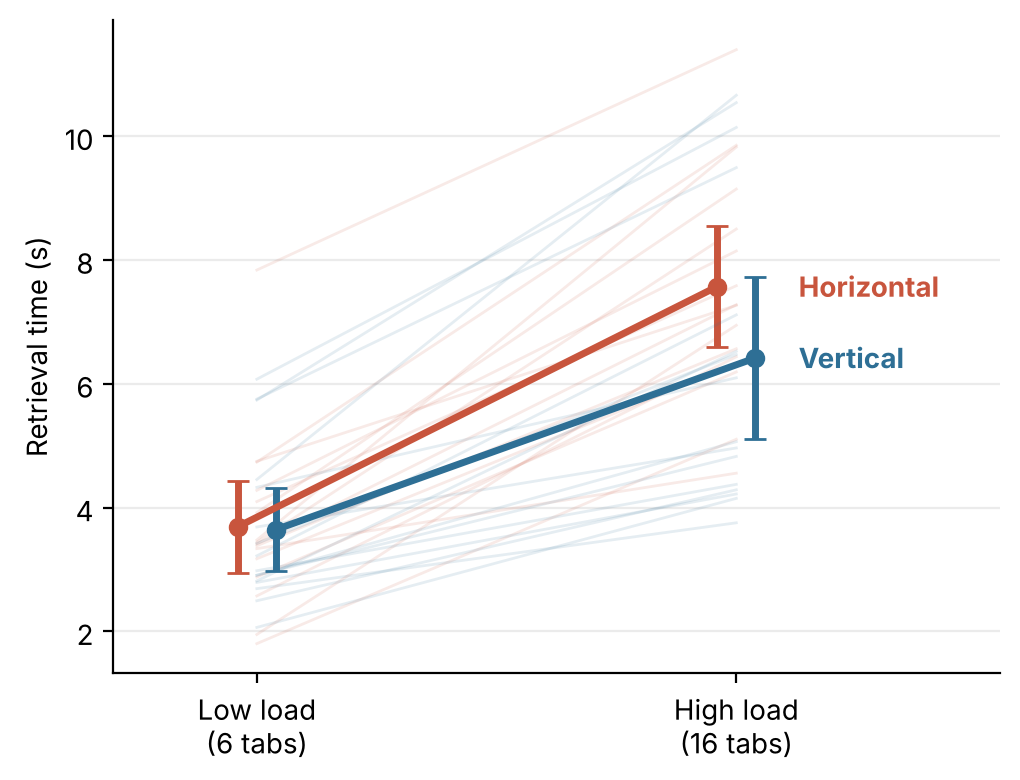

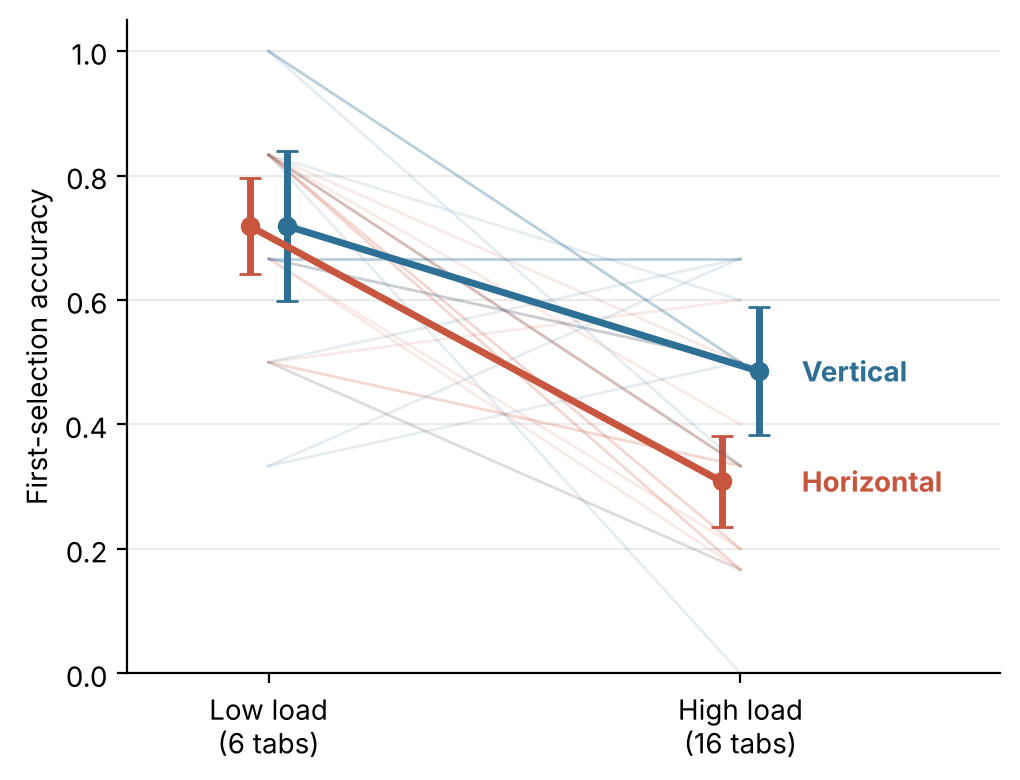

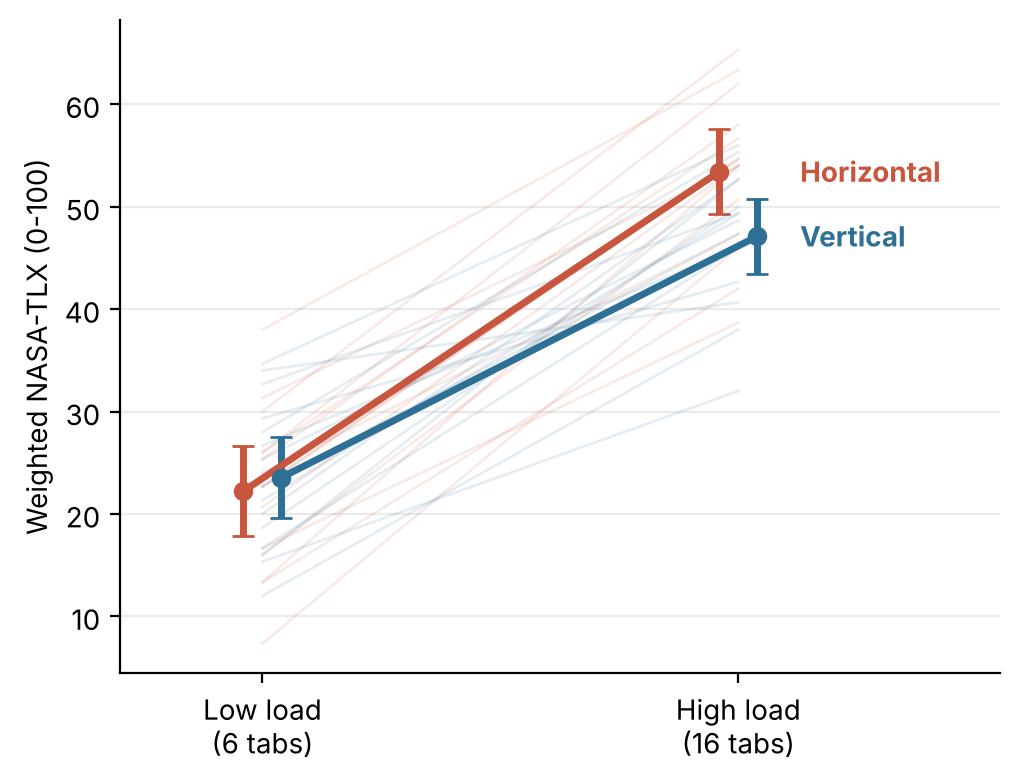

In [4]:
def mean_ci(x):
    x = x.dropna(); n = len(x)
    m = x.mean(); half = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return m, half

def interaction_plot(col, ylabel, ax=None, ylim=None):
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(5.2, 4))
    xpos = {l: i for i, l in enumerate(LOADS)}
    for o in ORIENTS:
        d = cond[cond["orientation"] == o]
        # faint participant lines
        for _, p in d.groupby("participant"):
            p = p.set_index("tab_load").reindex(LOADS)
            ax.plot([xpos[l] for l in LOADS], p[col].values, color=COLOR[o], alpha=0.12, lw=1)
        # mean +/- 95% CI (slightly offset so the two error bars do not overlap)
        off = -0.04 if o == "H" else 0.04
        ms, hs = zip(*[mean_ci(d.loc[d["tab_load"] == l, col]) for l in LOADS])
        ax.errorbar([xpos[l] + off for l in LOADS], ms, yerr=hs, color=COLOR[o], lw=2.5, marker="o", ms=6, capsize=4)
        ax.text(1.13, ms[1], ORIENT_NAME[o], color=COLOR[o], va="center", fontweight="bold")   # label clear of both error bars
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Low load\n(6 tabs)", "High load\n(16 tabs)"])
    ax.set_xlim(-0.3, 1.55); ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
    if own:
        fig.tight_layout(); return fig

for col, label in OUTCOMES.items():
    fig = interaction_plot(col, label, ylim=(0, 1.05) if col == "first_try_accuracy" else None)
    fig.savefig(FIG_DIR / f"interaction_{col}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 3. Normality checks (paper 4.7.3)
A 2x2 repeated-measures ANOVA is a test on three **within-participant difference scores**, so those are what must be roughly normal - not the raw values.
For each participant, with `HL, HH, VL, VH` = their cell values:

| Effect | Difference score per participant |
|---|---|
| Orientation (H1) | mean(HL, HH) - mean(VL, VH) |
| Tab load (H2) | mean(HH, VH) - mean(HL, VL) |
| Interaction (H3) | (HH - VH) - (HL - VL): how the horizontal-vs-vertical gap changes from low to high load |

Done for retrieval time and weighted NASA-TLX separately. Accuracy is handled by the trial-level logistic model, so it is not checked here.
**Reading the Shapiro-Wilk p-value:** p < .05 = evidence the differences are *not* normal. p >= .05 does **not** prove normality - with 16 participants the test has little power, so the Q-Q plot matters as much as the p-value.

In [5]:
def wide(col):
    """participant x cell table of one outcome (columns HL, HH, VL, VH)."""
    w = cond.pivot(index="participant", columns="condition", values=col)
    return w[["H-L", "H-H", "V-L", "V-H"]].rename(columns=lambda c: c.replace("-", ""))

def diffs(w):
    """The three within-participant difference scores for a 2x2 repeated-measures design."""
    return pd.DataFrame({
        "Orientation (H - V)":        (w["HL"] + w["HH"]) / 2 - (w["VL"] + w["VH"]) / 2,
        "Tab load (high - low)":      (w["HH"] + w["VH"]) / 2 - (w["HL"] + w["VL"]) / 2,
        "Interaction ((HH-VH)-(HL-VL))": (w["HH"] - w["VH"]) - (w["HL"] - w["VL"]),
    })

def shapiro_table(d, label):
    rows = []
    for c in d.columns:
        x = d[c].dropna()
        W, p = stats.shapiro(x)
        rows.append({"outcome": label, "effect": c, "n": len(x), "skew": stats.skew(x), "W": W, "p": p,
                     "normality rejected (p<.05)": p < 0.05})
    return pd.DataFrame(rows)

def qq_grid(d, title, fname):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
    for ax, c in zip(axes, d.columns):
        x = d[c].dropna()
        stats.probplot(x, dist="norm", plot=ax)
        ax.get_lines()[0].set_markerfacecolor("#2E6F95"); ax.get_lines()[0].set_markeredgecolor("#2E6F95")
        ax.get_lines()[1].set_color("#888")
        ax.set_title(c, fontsize=10); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel("Sample difference")
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, y=1.02, fontweight="bold"); fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight"); plt.show()

### 3.1 Retrieval time

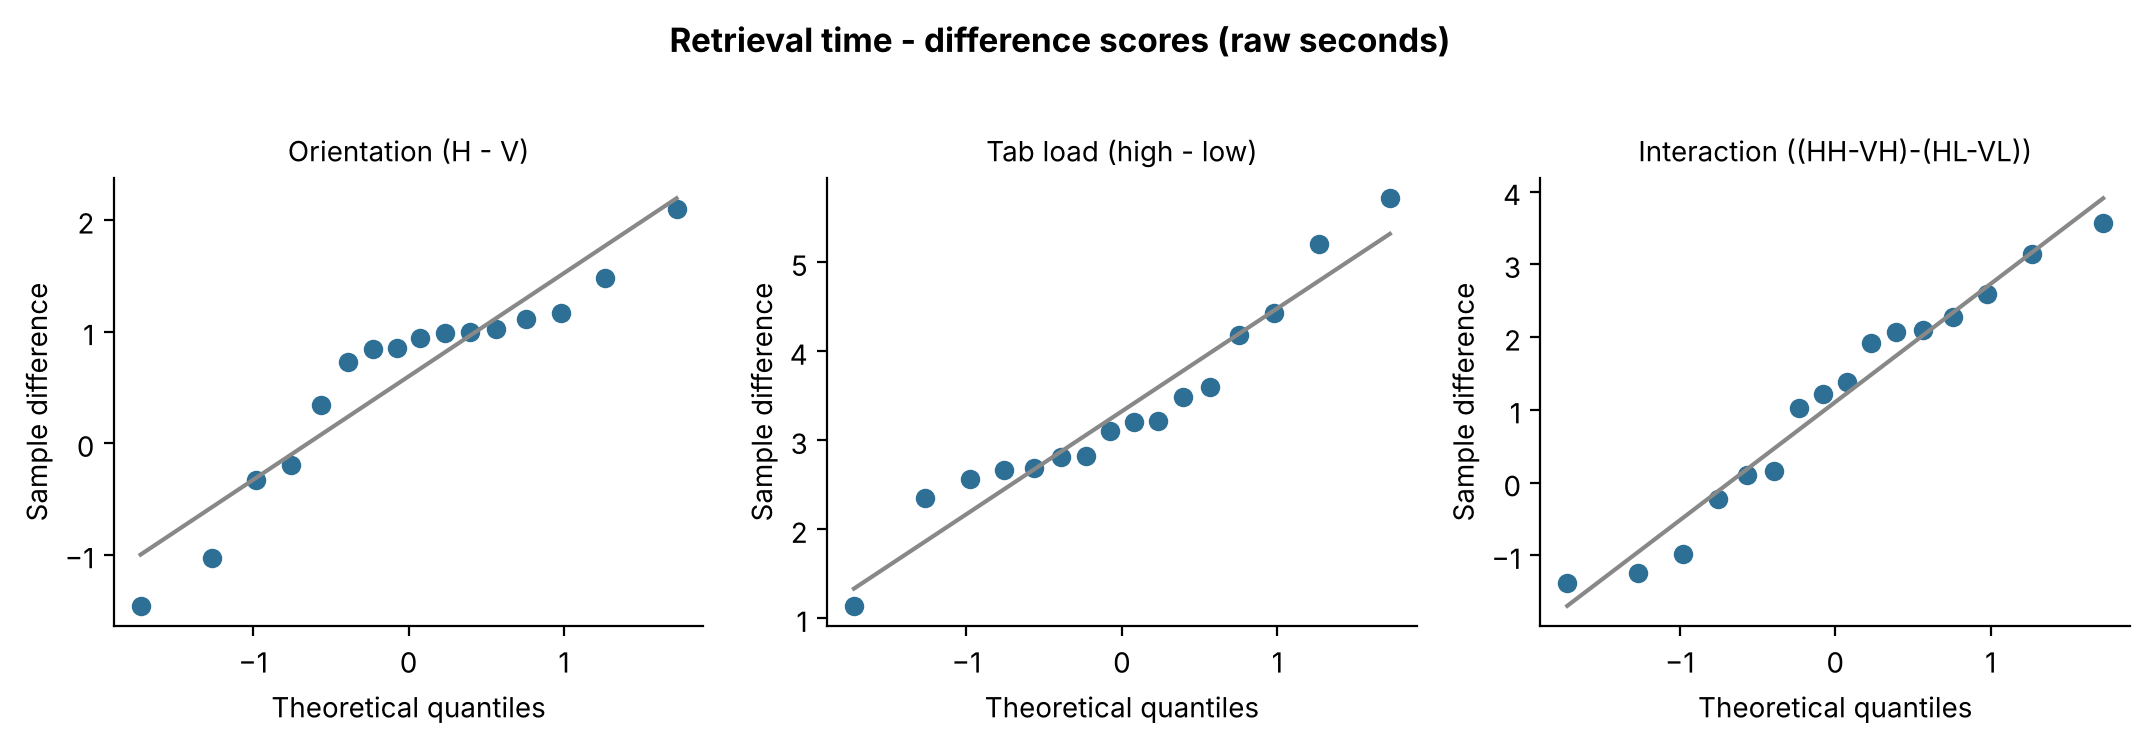

,outcome,effect,n,skew,W,p,normality rejected (p<.05)
0,Retrieval time (raw),Orientation (H - V),16,-0.839,0.899,0.076,False
1,Retrieval time (raw),Tab load (high - low),16,0.470,0.945,0.409,False
2,Retrieval time (raw),Interaction ((HH-VH)-(HL-VL)),16,-0.203,0.951,0.508,False


In [6]:
rt_w = wide("mean_rt_s")
assert rt_w.notna().all().all(), "a participant is missing a retrieval-time cell"
rt_d = diffs(rt_w)
rt_tab = shapiro_table(rt_d, "Retrieval time (raw)")
qq_grid(rt_d, "Retrieval time - difference scores (raw seconds)", "qq_retrieval_time_raw.png")
rt_tab.round(3)

**Log transformation (the paper allows it if retrieval times are skewed).** Times are positive and typically right-skewed, so differences of *log* times (ratios) are often closer to normal.
The check is repeated on the log scale and shown next to the raw result so the choice can be justified. The decision is made here, before any hypothesis test, and then applied to the whole analysis.

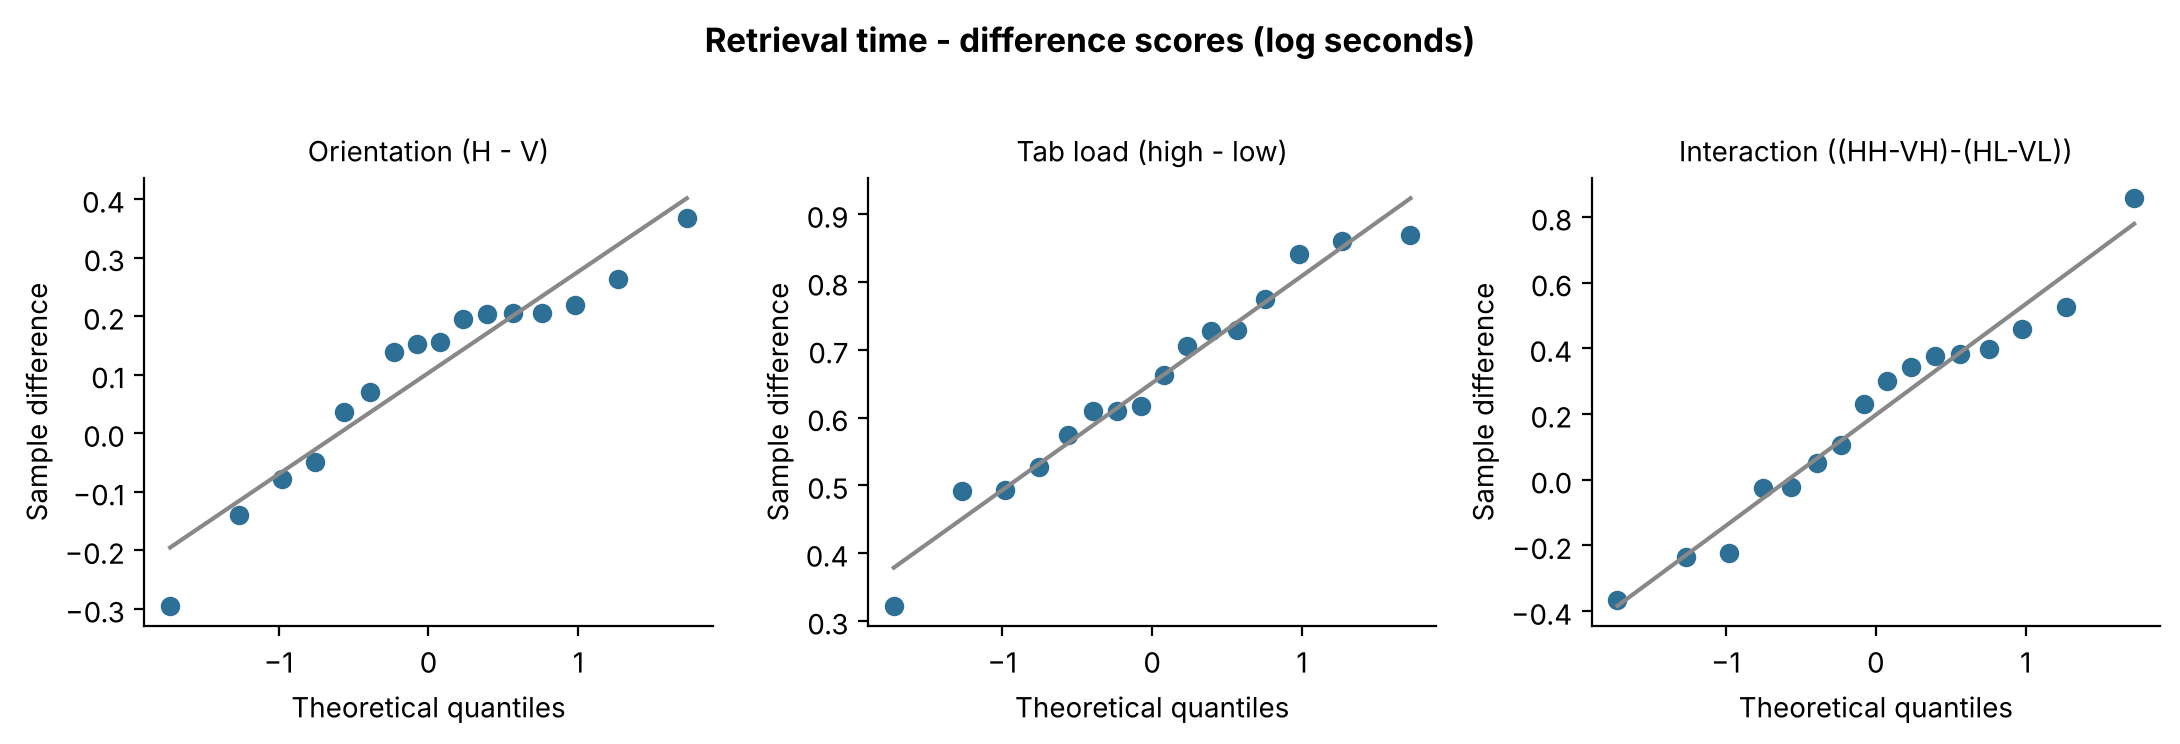

,outcome,effect,n,skew,W,p,normality rejected (p<.05)
0,Retrieval time (log),Orientation (H - V),16,-0.826,0.923,0.187,False
1,Retrieval time (log),Tab load (high - low),16,-0.331,0.964,0.736,False
2,Retrieval time (log),Interaction ((HH-VH)-(HL-VL)),16,0.007,0.969,0.823,False


In [7]:
rt_log_d = diffs(np.log(rt_w))
rt_log_tab = shapiro_table(rt_log_d, "Retrieval time (log)")
qq_grid(rt_log_d, "Retrieval time - difference scores (log seconds)", "qq_retrieval_time_log.png")
rt_log_tab.round(3)

### 3.2 Weighted NASA-TLX

Weighted TLX: 15 of 16 participants have all 4 conditions (excluded: ['DUMMY013'])


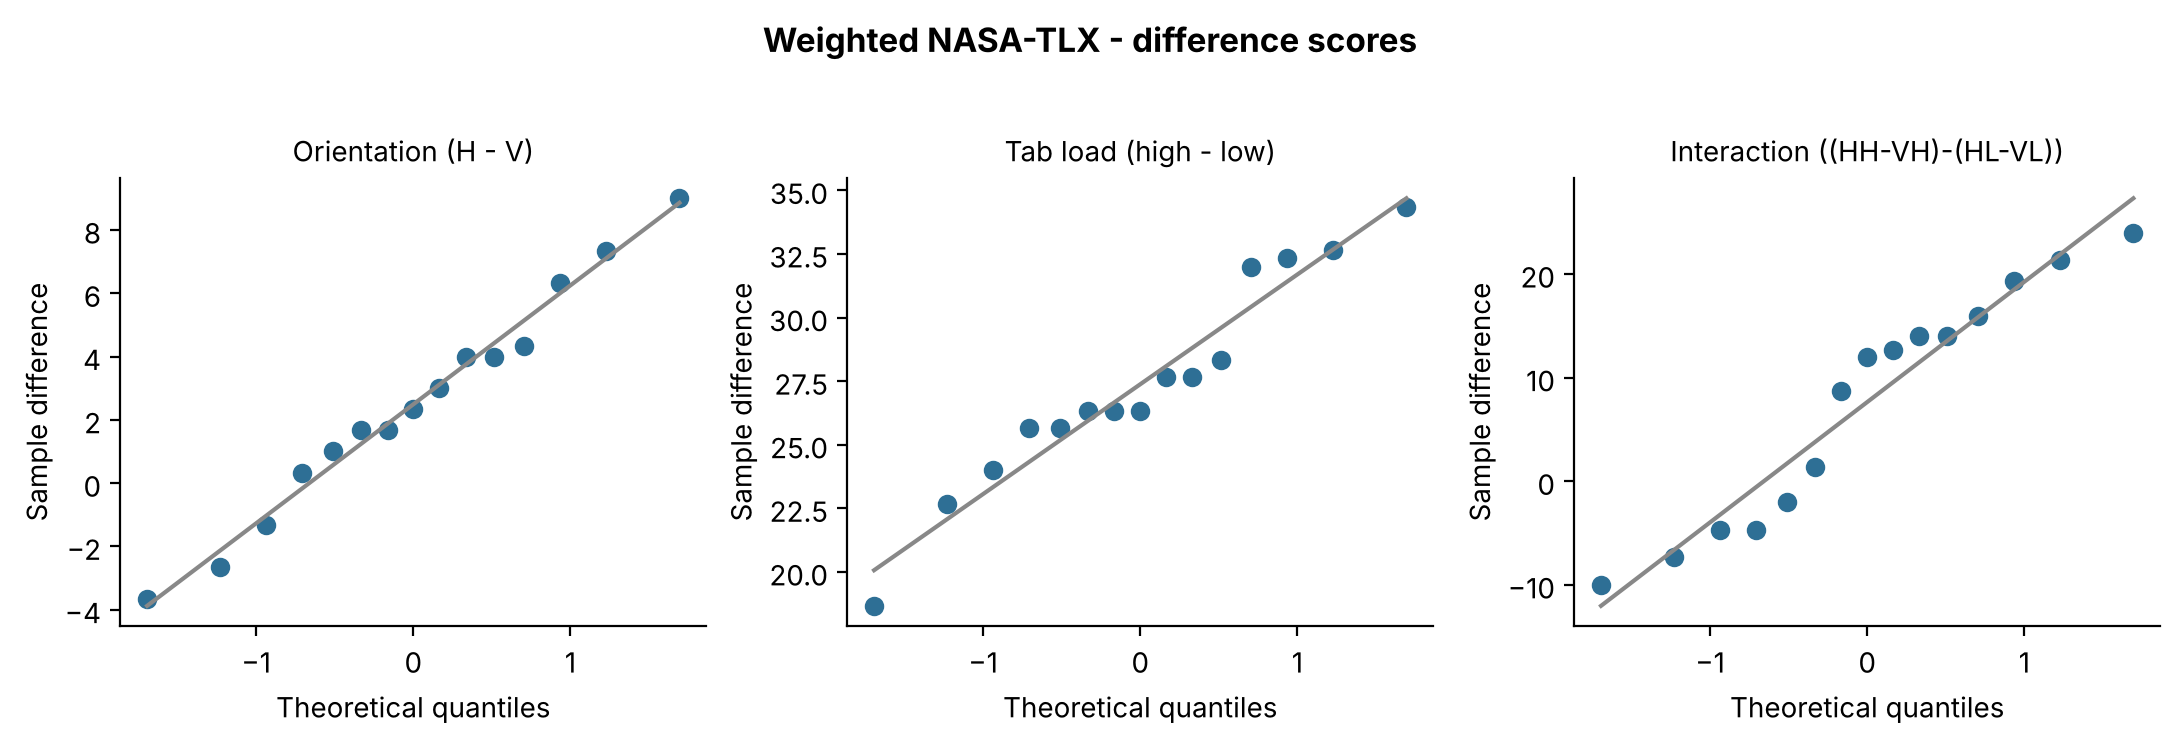

,outcome,effect,n,skew,W,p,normality rejected (p<.05)
0,Weighted NASA-TLX,Orientation (H - V),15,0.032,0.983,0.987,False
1,Weighted NASA-TLX,Tab load (high - low),15,-0.115,0.952,0.558,False
2,Weighted NASA-TLX,Interaction ((HH-VH)-(HL-VL)),15,-0.204,0.924,0.220,False


In [8]:
tlx_w = wide("weighted_tlx")
n_before = len(tlx_w)
tlx_w = tlx_w.dropna()                       # repeated-measures needs all 4 cells -> complete cases only
print(f"Weighted TLX: {len(tlx_w)} of {n_before} participants have all 4 conditions (excluded: "
      f"{sorted(set(cond['participant']) - set(tlx_w.index))})")
tlx_d = diffs(tlx_w)
tlx_tab = shapiro_table(tlx_d, "Weighted NASA-TLX")
qq_grid(tlx_d, "Weighted NASA-TLX - difference scores", "qq_weighted_tlx.png")
tlx_tab.round(3)

## 4. Summary: which route does each outcome take?
The paper: parametric route = two-way repeated-measures ANOVA; non-parametric route = aligned rank transform (ART) ANOVA. The rule below is a **suggestion** to make the decision explicit; the final call (including the log transform) should be recorded and made *before* testing the hypotheses.

In [9]:
summary = pd.concat([rt_tab, rt_log_tab, tlx_tab], ignore_index=True)
route = (summary.groupby("outcome")["normality rejected (p<.05)"].any()
         .map({True: "non-parametric (ART ANOVA)", False: "parametric (RM ANOVA)"}).rename("suggested route"))
n_rej = summary.groupby("outcome")["normality rejected (p<.05)"].sum().rename("effects with normality rejected (of 3)")
decision = pd.concat([n_rej, route], axis=1)
decision.to_csv(TAB_DIR / "normality_route_summary.csv")
summary.round(4).to_csv(TAB_DIR / "normality_shapiro_all.csv", index=False)
decision

,effects with normality rejected (of 3),suggested route
outcome,,
Retrieval time (log),0,parametric (RM ANOVA)
Retrieval time (raw),0,parametric (RM ANOVA)
Weighted NASA-TLX,0,parametric (RM ANOVA)


**How to read this:** an outcome goes non-parametric if *any* of its three difference scores fails the Shapiro-Wilk test, because a single ANOVA is used for all three effects.
If raw retrieval time fails but log retrieval time passes, the log-transformed parametric route is the natural choice.
Remember the small-sample caveat: borderline p-values should be settled with the Q-Q plots, and the reason recorded in the paper.